공식 홈페이지 (안내 페이지): Toronto대학교 Alex Krizhevsky 교수 홈페이지 [링크 텍스트](https://cave.cs.toronto.edu/kriz/cifar.html)

[124] 소스 코드 Ⅱ-68 모델 생성하기

In [1]:
from keras.datasets import cifar10
(X_train, y_train), (X_test, y_test) = cifar10.load_data()
_train = X_train/255
X_test = X_test/255
from keras.models import Sequential
from keras.layers import Flatten, Dense, Conv2D, MaxPooling2D
model=Sequential()
model.add(Conv2D(input_shape = (32, 32, 3), filters = 64, kernel_size = (3, 3), padding = 'same', activation = 'relu'))
model.add(MaxPooling2D(pool_size = (2, 2)))
model.add(Conv2D(filters = 64, kernel_size = (2, 2), padding = 'same', activation = 'relu'))
model.add(MaxPooling2D(pool_size = (2, 2)))
model.add(Conv2D(filters = 128, kernel_size = (3, 3), padding = 'same', activation = 'relu'))
model.add(MaxPooling2D(pool_size = (2, 2)))
model.add(Flatten())
model.add(Dense(512, activation = 'relu'))
model.add(Dense(200, activation = 'relu'))
model.add(Dense(10, activation = 'softmax'))
model.compile(loss = 'sparse_categorical_crossentropy', optimizer = 'adam', metrics = ['accuracy'])
model.fit(X_train, y_train, epochs = 10)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 542s 3us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 174s 109ms/step - accuracy: 0.4579 - loss: 1.6475
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 190s 102ms/step - accuracy: 0.5967 - loss: 1.1435
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 217s 112ms/step - accuracy: 0.6563 - loss: 0.9837
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 180s 115ms/step - accuracy: 0.6981 - loss: 0.8698
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 196s 111ms/step - accuracy: 0.7303 - loss: 0.7728
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 163s 105ms/step - accuracy: 0.7631 - loss: 0.6830
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 160s 102ms/step - accuracy: 0.7886 - loss: 0.6068
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 161s 103ms/step - accuracy: 0.8123 - loss: 0.5443
Epoch 9/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 160s 102ms/step - accuracy: 0.8360 - loss: 0.4772
Epoch 10/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 158s 101ms/step - accuracy: 0.8531 - loss: 0.4250



[124] 소스 코드 Ⅱ-69 모델의 성능 평가하기

In [3]:
model.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.1000 - loss: 2.8698


[2.8698205947875977, 0.10000000149011612]

[124] 소스 코드 Ⅱ-70 데이터 확인하기

In [15]:
import os
import urllib.request

# 1. ./data 폴더 생성 (이미 존재하면 무시)
os.makedirs("./data", exist_ok=True)

# 2. milknew.csv 파일을 ./data/milknew.csv 경로로 다운로드
url = "https://raw.githubusercontent.com/seongui2030/Section2/main/animal.jpg"
urllib.request.urlretrieve(url, "./data/animal.jpg")
print("다운로드 완료!")

다운로드 완료!


(1080, 1440)


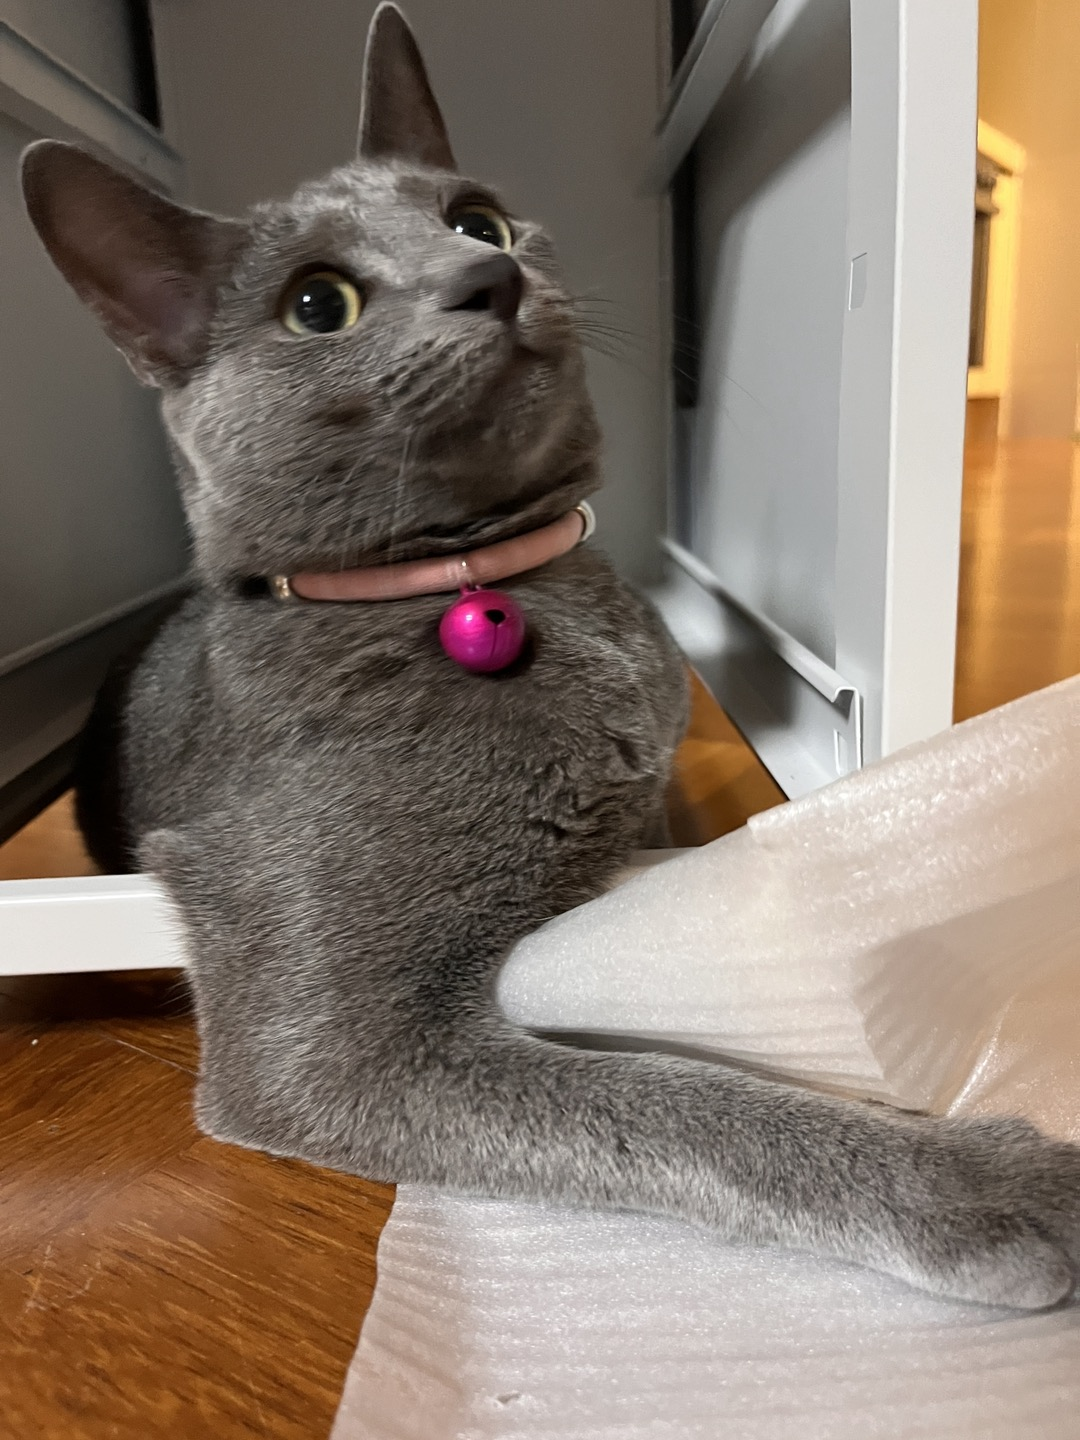

In [16]:
from PIL import Image
animal = Image.open('/content/data/animal.jpg')
print(animal.size)
animal

[124] 소스 코드 Ⅱ-71 데이터 전처리하기(이미지 크기 변경)

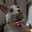

In [17]:
animal_crop = animal.crop((40, 40, 800, 800))
animal32 = animal_crop.resize((32, 32))
animal32

[125] 소스 코드 Ⅱ-72 데이터 전처리하기(이미지 형태 변경)

In [18]:
import numpy as np
test_img = np.array(animal32)
test_img.shape

(32, 32, 3)

[125] 소스 코드 Ⅱ-73 데이터 전처리하기(이미지 차원과 범위 변경)

In [19]:
test_img = test_img.reshape(1, 32, 32, 3)
test_img = test_img/255
test_img.shape

(1, 32, 32, 3)

[125] 소스 코드 Ⅱ-74 모델 활용하기

In [20]:
result = model.predict(test_img)
n = np.argmax(result)
n

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step


np.int64(3)

[125] 소스 코드 Ⅱ-75 예측 결과 출력하기

In [21]:
cifar_class = ['airplane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
cifar_class[n]

'cat'

## 이미 학습된 모델을 파일로 저장하고, 나중에 불러와서 새로운 데이터로 추가 학습(전이 학습 / Fine-tuning)을 진행

In [ ]:
# 1. 학습 완료된 모델 저장하기: 학습이 끝난 모델 객체를 .keras 또는 .h5 확장자로 저장합니다.
# 모델 저장
model.save("cifar10_model.keras")
model.save("cifar10_model.h5")
print("모델이 성공적으로 저장되었습니다!")

In [6]:
# 2. 저장된 모델 불러오기: 이어서 학습하고 싶을 때 모델을 불러오는 함수, keras.models의 load_model 함수를 사용
from tensorflow.keras.models import load_model

# 저장된 모델 불러오기
model = load_model("cifar10_model.keras")
print("모델을 불러왔습니다!")

모델을 불러왔습니다!


## 새로운 이미지를 업로드하고 전처리한 뒤 X_new, y_new 형태를 갖추어 추가 학습까지 진행하는 전체 과정

In [8]:
from google.colab import files
import os

# 1. 파일 업로드 실행 (새로 학습할 이미지 선택)
uploaded = files.upload()

# 2. 업로드된 파일 이름을 변수로 지정 (예: 'my_new_image.jpg'라고 가정)
# 업로드된 파일명 확인 후 아래 파일명을 실제 파일명으로 수정해 주세요.
filename = list(uploaded.keys())[0]
print(f"업로드된 파일 이름: {filename}")

Saving animal.jpg to animal.jpg
업로드된 파일 이름: animal.jpg


In [9]:
from PIL import Image
import numpy as np

# 1. PIL을 이용해 이미지 불러오기
img = Image.open(filename)

# 2. 모델이 요구하는 크기(32x32)로 리사이즈
# (필요시 앞서 하셨던 것처럼 crop() 과정을 먼저 거치셔도 됩니다)
img_resized = img.resize((32, 32))

# 3. 넘파이 배열로 변환
img_array = np.array(img_resized)

# 4. 흑백이거나 투명도(RGBA)가 포함된 이미지일 경우 RGB 3채널로 변환 예외 처리
if len(img_array.shape) == 2:  # 흑백인 경우
    img_array = np.stack((img_array,)*3, axis=-1)
elif img_array.shape[2] == 4:  # 투명도(Alpha) 채널이 있는 경우
    img_array = img_array[:, :, :3]

# 5. 모델 입력 형태(1, 32, 32, 3)로 차원 추가 및 0~255 범위를 0~1 사이로 정규화
X_new = img_array.reshape(1, 32, 32, 3)
X_new = X_new / 255.0

print(f"전처리된 X_new 형태(Shape): {X_new.shape}")

전처리된 X_new 형태(Shape): (1, 32, 32, 3)


In [10]:
# cifar_class = ['airplane(0)', 'car(1)', 'bird(2)', 'cat(3)', 'deer(4)', 'dog(5)', 'frog(6)', 'horse(7)', 'ship(8)', 'truck(9)']
# 예를 들어 업로드한 이미지가 '고양이(3)'라면:
y_new = np.array([3])

print(f"지정된 y_new 값: {y_new}")

지정된 y_new 값: [3]


In [11]:
from tensorflow.keras.models import load_model

# 1. 저장된 모델 불러오기
model = load_model("cifar10_model.keras")

# 2. 새로운 데이터로 추가 학습(Fine-tuning) 진행
model.fit(X_new, y_new, epochs=5)

print("새로운 데이터 추가 학습 완료!")

Epoch 1/5
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.0000e+00 - loss: 1.8411
Epoch 2/5
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.0000e+00 - loss: 1.7318
Epoch 3/5
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step - accuracy: 0.0000e+00 - loss: 1.5468
Epoch 4/5
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.0000e+00 - loss: 1.3802
Epoch 5/5
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 1.0000 - loss: 1.1517
새로운 데이터 추가 학습 완료!


## 여러 장의 이미지를 한꺼번에 업로드하고 일괄 전처리한 뒤 추가 학습까지 진행하는 전체 과정

In [13]:
# # 여러 장의 이미지로 모델 추가 학습(Fine-tuning)하는 전체 과정

# 이 문서는 Colab 환경에서 여러 장의 새로운 이미지 폴더를 활용해 CIFAR-10 모델을 일괄 전처리하고 추가 학습을 진행하는 전체 파이썬 코드입니다.

# ## 1단계: 새로운 이미지들을 담을 폴더 생성 및 업로드
# 여러 장의 이미지를 저장할 폴더를 만들고 이미지 파일을 업로드합니다.

import os
from google.colab import files

# 1. 다수의 이미지를 업로드할 폴더 생성
os.makedirs("./new_images", exist_ok=True)

# 2. 파일 업로드 실행 (여러 장의 이미지 파일 선택)
print("업로드할 이미지들을 선택해 주세요:")
uploaded = files.upload()

# 3. 업로드된 파일들을 ./new_images 폴더로 이동 또는 위치 확인
for filename in uploaded.keys():
    print(f"업로드 완료된 파일: {filename}")

업로드할 이미지들을 선택해 주세요:


KeyboardInterrupt: 

In [ ]:
###############################################
# 2단계: 여러 장의 이미지 일괄 전처리 (크기 변경 및 정규화)
# 폴더 내 모든 이미지를 불러와 모델이 요구하는 입력 크기(32x32, 0~1 정규화)로 변환한 뒤
# 하나의 넘파이 배열(X_new)로 통합합니다.
###############################################
import os
from PIL import Image
import numpy as np

image_dir = "./new_images"
image_list = []
labels_list = []

# 폴더 내 모든 이미지 파일 순회
for filename in os.listdir(image_dir):
    if filename.lower().endswith(('.png', '.jpg', '.jpeg')):
        img_path = os.path.join(image_dir, filename)

        # 1. 이미지 열기 및 크기 변경 (32x32)
        img = Image.open(img_path)
        img_resized = img.resize((32, 32))

        # 2. 넘파이 배열 변환 및 채널 보정 (RGB)
        img_array = np.array(img_resized)
        if len(img_array.shape) == 2:  # 흑백인 경우
            img_array = np.stack((img_array,)*3, axis=-1)
        elif img_array.shape[2] == 4:  # 투명도 채널(RGBA) 제거
            img_array = img_array[:, :, :3]

        image_list.append(img_array)

        # 3. 라벨(정답) 지정 예시 (예: 고양이 이미지라면 정답 레이블 3 부여)
        labels_list.append(3)

# 4. 리스트를 최종 넘파이 배열로 변환 및 정규화 (0~1 범위)
X_new = np.array(image_list, dtype=np.float32) / 255.0
y_new = np.array(labels_list, dtype=np.int32)

print(f"통합된 X_new 형태(Shape): {X_new.shape}")
print(f"통합된 y_new 형태(Shape): {y_new.shape}")

In [ ]:
###################################
# 3단계: 저장된 모델 불러와서 일괄 추가 학습 진행하기
# 준비된 대량의 새로운 데이터(X_new, y_new)를 이용해 저장된 모델을 불러와 추가 학습(Fine-tuning)을 수행합니다.
#############################
from tensorflow.keras.models import load_model

# 1. 저장된 모델 불러오기
model = load_model("cifar10_model.keras")
print("모델을 성공적으로 불러왔습니다!")

# 2. 여러 장의 새로운 데이터로 추가 학습 진행
model.fit(X_new, y_new, epochs=5, batch_size=32)

print("여러 장의 이미지로 추가 학습이 완료되었습니다!")